# Moneyball FC – who replaces Higuaín?

This notebook tells the whole analysis in the order of the data-analysis life cycle:
question → data → preparation → analysis → insight → recommendation → limitations.

## 1. Business question

Summer 2016: Napoli lose **Gonzalo Higuaín** to Juventus after a record Serie A season.
As the scouting analyst, using Serie A 2015/16 data, this notebook answers the question: **which players contribute attacking
output at a high rate per 90 minutes, have a profile close to Higuaín, and is that output
sustainable or just luck?**

| Sub-question | Method |
|---|---|
| SQ1 Finishing – who scores above/below expectation (goals vs npxG), and is the gap outside the range of luck? | Monte Carlo simulation |
| SQ2 Output – who creates and takes the best chances per 90, compared with the same position? | per-90 metrics + percentile within position group |
| SQ3 Replacement – whose statistical profile is closest to Higuaín's? | standardised metric vector + cosine similarity |

**Hypotheses**

- **H1** Most players' goal totals sit inside the 90% band simulated from their xG: the gap is mostly luck.
- **H2** At least one forward from a mid-table club reaches the 80th percentile of npxG/90 among forwards.
- **H3** The players most similar to Higuaín share a high xG per shot (good shooting positions), not just many shots.

## 2. Setup

In [1]:
%load_ext autoreload
%autoreload 2
# Show matplotlib figures returned by the plots module as images below each cell.
%matplotlib inline

import sys
from pathlib import Path

# Add the project root to sys.path so that the moneyball package can be imported.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd

from moneyball import analysis, metrics, plots, processing
from moneyball.config import (
    MIN_MINUTES,
    PERCENTILE_METRICS,
    SHORTLIST,
    SIMILARITY_METRICS,
    TARGET_PLAYER,
)
from moneyball.data_loader import StatsBombClient, load_tables

pd.set_option("display.precision", 2)
pd.set_option("display.max_columns", 25)

## 3. Data

Source: [StatsBomb Open Data](https://github.com/statsbomb/open-data), Serie A 2015/16,
380 matches, JSON events (~3 MB per match, ~1.2 GB in total) and lineups.
`StatsBombClient` downloads a file once, caches it in `data/raw/`
and raises a readable `StatsBombError` if an error appears. Here we only demo one match.

In [2]:
client = StatsBombClient()
raw_events = client.get_events(3879608)  # Hellas Verona - Bologna
raw_lineups = client.get_lineups(3879608)
print(f"{len(raw_events)} events, first event keys: {list(raw_events[0])[:8]}")

3733 events, first event keys: ['id', 'index', 'period', 'timestamp', 'minute', 'second', 'type', 'possession']


In [3]:
tables = load_tables()
{name: table.shape for name, table in tables.items()}

{'matches': (380, 7),
 'events': (857699, 29),
 'appearances': (10598, 7),
 'player_season': (551, 23)}

## 4. Preparation

**Flattening.** Each event is a nested dict; `events_to_dataframe` flattens it with
`pd.json_normalize`, keeps the event types and columns we need, and splits `[x, y]` lists into
numeric columns.

In [4]:
sample_events = processing.events_to_dataframe(raw_events, 3879608) #Bologna vs Herona
print("Before: one nested dict ->", {k: raw_events[100][k] for k in ["type", "location"]})
sample_events[sample_events["type_name"] == "Shot"][
    ["minute", "player_name", "x", "y", "shot_statsbomb_xg", "shot_outcome_name"]
].head()

Before: one nested dict -> {'type': {'id': 16, 'name': 'Shot'}, 'location': [106.3, 33.1]}


,minute,player_name,x,y,shot_statsbomb_xg,shot_outcome_name
63,1,Giampaolo Pazzini,106.3,33.1,0.04,Off T
140,3,Mattia Destro,86.6,44.5,0.02,Off T
174,5,Emanuele Giaccherini,108.4,32.7,0.10,Goal
348,9,Giampaolo Pazzini,95.7,34.8,0.05,Saved
442,13,Mattia Destro,102.8,38.3,0.08,Wayward


**Minutes played** (every per-90 metric is divided by it). Each lineup entry lists position
spells with `from`/`to` clocks; `to = None` means "until the final whistle", taken from the
second-half `Half End` event (95:08 here).

In [5]:
end_minute = processing.match_end_minute(sample_events)
sample_appearances = processing.lineups_to_appearances(raw_lineups, 3879608, end_minute)
print(f"Match length: {end_minute:.2f} min")
sample_appearances.sort_values("minutes").head(6)

Match length: 95.13 min


,match_id,player_id,player_name,team_name,position,position_group,minutes
20,3879608,26220,Matuzalém Francelino da Silva,Hellas Verona,Center Defensive Midfield,MID,16.68
14,3879608,8851,Saphir Sliti Taïder,Bologna,Right Center Midfield,MID,19.50
25,3879608,34565,Anthony Mounier,Bologna,Left Wing,WING,24.38
8,3879608,7949,Artur Ioniţă,Hellas Verona,Right Center Midfield,MID,28.67
19,3879608,18027,Matteo Brighi,Bologna,Left Center Midfield,MID,34.27
17,3879608,11494,Luca Siligardi,Hellas Verona,Center Attacking Midfield,MID,36.23


In [6]:
sample_appearances.groupby("team_name")["minutes"].sum() / end_minute  # ~11 players on the pitch

team_name
Bologna          11.00
Hellas Verona    10.96
Name: minutes, dtype: float64

**Player-season table.** One row per player: totals, then per-90 values for players with at
least 900 minutes (≈ 10 full matches).

In [7]:
season = tables["player_season"]
players = metrics.add_per90(season, min_minutes=MIN_MINUTES)
print(f"{len(season)} players played, {len(players)} kept with >= {MIN_MINUTES} minutes")
players.sort_values("np_goals", ascending=False)[
    ["player_name", "team_name", "minutes", "np_goals", "npxg", "npxg_p90", "xa_p90"]
].head(8)

551 players played, 343 kept with >= 900 minutes


,player_name,team_name,minutes,np_goals,npxg,npxg_p90,xa_p90
22,Gonzalo Gerardo Higuaín,Napoli,3065.50,33,22.68,0.67,0.07
39,Carlos Arturo Bacca Ahumada,AC Milan,3263.97,16,13.84,0.38,0.10
80,Mauro Emanuel Icardi Rivero,Inter Milan,2666.08,15,10.79,0.36,0.14
193,Leonardo Pavoletti,Genoa,2074.40,14,10.73,0.47,0.06
9,Mohamed Salah,AS Roma,2796.52,14,8.50,0.27,0.20
43,Paulo Bruno Exequiel Dybala,Juventus,2511.63,13,10.09,0.36,0.30
106,Nikola Kalinić,Fiorentina,2701.50,12,14.33,0.48,0.03
318,Massimo Maccarone,Empoli,2830.00,12,8.37,0.27,0.08


## 5. Analysis

### SQ1 – Finishing: skill or luck?

Each non-penalty shot is a Bernoulli trial with success probability = its xG. Simulating
10,000 seasons gives the goals an average finisher would score from the same chances.

In [8]:
shots = analysis.non_penalty_shots(tables["events"])
finishing = analysis.finishing_table(shots, players)
print(finishing["verdict"].value_counts().to_dict())
finishing.head(6)

{'within': 155, 'above': 5, 'below': 3}


,player_id,player_name,team_name,position_group,shots,goals,npxg,expected,low,high,p_at_least,p_at_most,verdict
0,7022,Jesús Joaquín Fernández Sáez de la Torre,Genoa,FWD,39,6,2.03,2.04,0.0,4.0,9.70e-03,1.00,above
1,5497,Gonzalo Gerardo Higuaín,Napoli,FWD,179,33,22.68,22.75,16.0,30.0,1.17e-02,0.99,above
2,3531,Mohamed Salah,AS Roma,WING,73,14,8.50,8.49,5.0,13.0,2.57e-02,0.99,above
3,6964,Alessandro Florenzi,AS Roma,DEF,48,7,3.26,3.25,1.0,6.0,3.13e-02,0.99,above
4,7775,Emanuele Giaccherini,Bologna,WING,46,7,3.53,3.51,1.0,6.0,4.68e-02,0.99,above
5,6947,Miralem Pjanić,AS Roma,MID,67,9,5.28,5.31,2.0,9.0,7.01e-02,0.97,within


In [9]:
fig = plots.goals_vs_xg_scatter(players, highlight=[TARGET_PLAYER])
fig

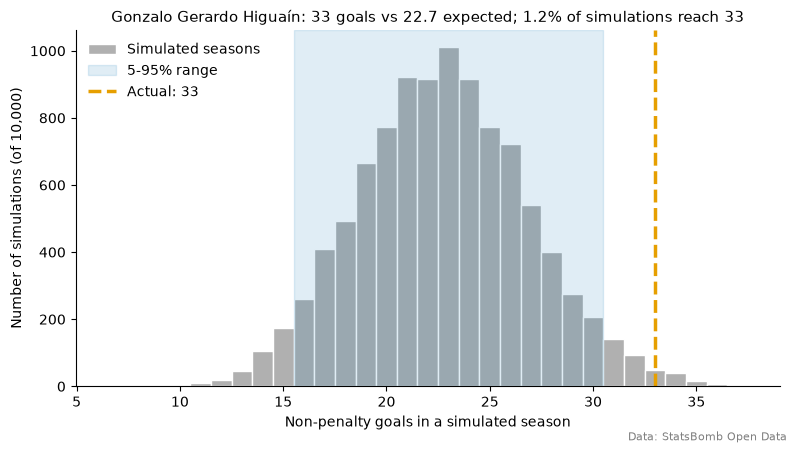

In [10]:
target = analysis.find_player(players, TARGET_PLAYER)
sims, actual = analysis.simulate_player(shots, target["player_id"])
fig = plots.simulation_histogram(sims, actual, TARGET_PLAYER)
fig

**Explanation** 155 of 163 simulated players (95%) are inside their 5–95% band, slightly *more*
than the 90% expected by chance: H1 is supported, goal-vs-xG gaps are mostly luck. Higuaín
is one of the 5 above the band: 33 non-penalty goals from 22.7 npxG; only ~1% of simulated
seasons reach 33. With 163 players tested, a few such flags happen by chance, so this is a
strong signal, not proof.

### SQ2 – Output per 90 compared with the same position

In [11]:
percentiles = analysis.position_percentiles(players, PERCENTILE_METRICS)
percentiles[percentiles["player_name"] == TARGET_PLAYER][
    ["metric", "value", "percentile", "zscore"]
]

,metric,value,percentile,zscore
22,np_goals_p90,0.97,100.00,4.37
365,npxg_p90,0.67,100.00,3.50
708,np_shots_p90,5.26,100.00,3.48
1051,npxg_per_shot,0.13,58.82,0.15
1394,xa_p90,0.07,37.25,-0.59
1737,key_passes_p90,1.44,78.43,0.51
2080,progressive_carries_p90,2.76,80.39,0.73
2423,dribbles_completed_p90,1.15,74.51,0.40
2766,pressures_p90,11.80,11.76,-1.17


In [12]:
fig = plots.percentile_bars(percentiles, TARGET_PLAYER)
fig

In [13]:
forwards_npxg = percentiles[
    (percentiles["metric"] == "npxg_p90") & (percentiles["position_group"] == "FWD")
]
forwards_npxg.sort_values("percentile", ascending=False).head(10)[
    ["player_name", "team_name", "value", "percentile", "zscore"]
]

,player_name,team_name,value,percentile,zscore
365,Gonzalo Gerardo Higuaín,Napoli,0.67,100.00,3.50
420,Edin Džeko,AS Roma,0.51,98.04,2.10
449,Nikola Kalinić,Fiorentina,0.48,96.08,1.78
536,Leonardo Pavoletti,Genoa,0.47,94.12,1.67
594,Josef Alexander Martínez Mencia,Torino,0.45,92.16,1.57
437,Duván Esteban Zapata Banguera,Udinese,0.41,90.20,1.15
350,Stevan Jovetić,Inter Milan,0.40,88.24,1.05
382,Carlos Arturo Bacca Ahumada,AC Milan,0.38,86.27,0.90
411,Alberto Paloschi,Chievo,0.37,84.31,0.79
423,Mauro Emanuel Icardi Rivero,Inter Milan,0.36,82.35,0.74


**Explanation.** Higuaín's 0.67 npxG/90 is 3.5 standard deviations above the forward average;
the next best (Džeko, 0.51) is far behind. Several forwards at mid-table clubs reach the 80th
percentile – Pavoletti (Genoa, 0.47), Martínez (Torino, 0.45), Zapata (Udinese, 0.41):
H2 is supported.

### SQ3 – Who plays like Higuaín?

Metrics are standardised (z-scores) so that large-scale metrics (pressures ≈ 12/90) do not
outweigh small ones (npxG/shot ≈ 0.1); cosine similarity then compares the *shape* of the
profiles.

In [14]:
similar_all = analysis.similar_players(players, TARGET_PLAYER, SIMILARITY_METRICS, top_n=None)
similar = similar_all.head(10)
similar[
    [
        "player_name",
        "team_name",
        "minutes",
        "similarity",
        "npxg_p90",
        "np_shots_p90",
        "npxg_per_shot",
    ]
]

,player_name,team_name,minutes,similarity,npxg_p90,np_shots_p90,npxg_per_shot
0,Edin Džeko,AS Roma,2087.27,0.87,0.51,3.71,0.14
1,Josef Alexander Martínez Mencia,Torino,985.47,0.85,0.45,3.20,0.14
2,Stevan Jovetić,Inter Milan,1573.28,0.70,0.40,3.95,0.10
3,Duván Esteban Zapata Banguera,Udinese,1584.50,0.62,0.41,2.95,0.14
4,Leonardo Pavoletti,Genoa,2074.40,0.54,0.47,2.91,0.16
5,Marco Borriello,Atalanta,1695.82,0.42,0.29,2.87,0.10
6,Mario Barwuah Balotelli,AC Milan,905.33,0.40,0.27,4.18,0.07
7,Nikola Kalinić,Fiorentina,2701.50,0.38,0.48,2.43,0.20
8,Giampaolo Pazzini,Hellas Verona,2005.30,0.35,0.33,3.41,0.10
9,Luca Toni,Hellas Verona,1847.12,0.34,0.36,2.83,0.13


In [15]:
fig = plots.radar_comparison(
    percentiles, [TARGET_PLAYER, *similar["player_name"].head(2)], PERCENTILE_METRICS
)
fig

**Explanation.** Higuaín's profile is defined by volume: 5.3 non-penalty shots per 90 (100th
percentile) with only an average npxG per shot (59th percentile). His closest matches (Džeko
0.87, Martínez 0.85) actually have higher xG per shot. H3 is rejected: what makes the
profile is shooting a lot from decent positions, not exceptional shot quality.

## 6. Insights

1. Higuaín's finishing is hard to explain by luck – and hard to replace. He scored 33
   non-penalty goals from 22.7 npxG (+10.3); only ~1% of 10,000 simulated seasons reach 33.
   Across the league, 95% of players sit inside their luck band, so a replacement's
   goal tally should be judged on npxG, not on goals.
2. No one matches his output; mid-table clubs have the best value options. Higuaín
   produced 0.67 npxG/90 (z = 3.5 among forwards). Pavoletti (0.47), Martínez (0.45) and
   Zapata (0.41) are all ≥ 90th percentile while playing for Genoa, Torino and Udinese.
3. His style is about shot volume, not shot quality. 5.3 shots/90 (100th percentile) but
   0.127 npxG/shot (59th). The two closest profiles, Džeko (0.87) and Martínez (0.85),
   shoot from better positions but less often.

## 7. Recommendation

In [16]:
# SHORTLIST (config.py) is chosen by hand from the SQ1-SQ3 tables above.
is_shortlisted = similar_all["player_name"].isin(SHORTLIST)
similar_all[is_shortlisted][
    ["player_name", "team_name", "minutes", "similarity", "npxg_p90", "np_shots_p90"]
]

,player_name,team_name,minutes,similarity,npxg_p90,np_shots_p90
1,Josef Alexander Martínez Mencia,Torino,985.47,0.85,0.45,3.20
3,Duván Esteban Zapata Banguera,Udinese,1584.50,0.62,0.41,2.95
4,Leonardo Pavoletti,Genoa,2074.40,0.54,0.47,2.91
9,Luca Toni,Hellas Verona,1847.12,0.34,0.36,2.83
10,Carlos Arturo Bacca Ahumada,AC Milan,3263.97,0.33,0.38,2.18


In [17]:
finishing[finishing["player_name"].isin(SHORTLIST)][
    ["player_name", "shots", "goals", "npxg"]
]

,player_name,shots,goals,npxg
14,Leonardo Pavoletti,67,14,10.73
38,Carlos Arturo Bacca Ahumada,79,16,13.84
58,Duván Esteban Zapata Banguera,52,8,7.20
133,Josef Alexander Martínez Mencia,35,3,4.98
144,Luca Toni,58,3,7.46


Shortlist (same position group, ≥ 80th percentile npxG/90, not at a top-5 club, ranked by
similarity). For each player the next step is video scouting and a price/age check – the
data is an input to the decision, not the decision:

- Josef Martínez (Torino) – closest profile (0.85), 0.45 npxG/90; only 985 minutes, so
  the sample is small: watch more matches before deciding.
- Duván Zapata (Udinese) – 0.41 npxG/90, 8 goals from 7.2 npxG: output matches his chances.
- Leonardo Pavoletti (Genoa) – best npxG/90 outside the top clubs (0.47), 14 goals from 10.7
  npxG, inside the luck band.
- Luca Toni (Hellas Verona) and Carlos Bacca (AC Milan) complete the list; Toni scored
  4.5 goals *below* his npxG and was 38 years old – exactly what the missing age data cannot show.

## 8. Limitations

- One season (2015/16): no trend across seasons; a player's year can be an outlier.
- No transfer fees, wages or ages: "not at a top-5 club" is only a proxy for affordable.
- Small samples: per-90 rates are noisy near the 900-minute threshold, which is itself a
  judgement call.
- Team style: individual numbers depend on tactics and team-mates (Napoli created a lot for
  Higuaín).